<!-- # Copyright (c) 2026 takotime808 -->
# Cost Savings: What `multioutreg` Saves in an Existing Workflow

Most engineering and science teams already have a workflow for expensive models: a simulator
(CFD, FEA, a process model) or a physical experiment, a design of experiments chosen up front
(often a full-factorial grid or a hand-picked set of cases), and a fixed run budget. This
notebook measures what changes when `multioutreg` is inserted into that workflow, in the
currency the workflow pays: **simulator runs**, converted to **money, wall-clock time and
core-hours** through a cost model you can edit.

Every number below is *measured*, not assumed: each scenario runs the existing-workflow
baseline and the `multioutreg` alternative on an analytic benchmark whose true answer is
known, and counts how many runs each needs to reach the same accuracy. The benchmarks stand in
for the expensive model; the analytic functions cost nothing to evaluate, so the comparison
is exact. A summary of the results is on the [Cost Savings and ROI](../cost_savings.md) page.

**Scenarios**

1. [The cost model](#cost-model): turn runs into dollars, hours and core-hours
2. [Many-query analysis](#mc): Monte Carlo uncertainty propagation on a surrogate instead of the simulator
3. [Building a surrogate](#al): grids, random, Sobol and active-learning designs, and when to stop
4. [Design optimization](#opt): Bayesian optimization against random search and grids
5. [Multi-fidelity](#mf): spending most of the budget on a cheap model
6. [Model-selection compute](#screen): statistical pre-screening before the model search
7. [The ledger](#ledger): all savings in one table
8. [Plugging into your pipeline](#integration): the `ask` / `tell` loop for jobs that run outside Python
9. [When the savings disappear](#caveats)

Medians over seeds are reported throughout; the number of seeds is kept small so the notebook
runs in about ten minutes on a laptop.

In [1]:
import time
import warnings

warnings.filterwarnings("ignore")  # GP optimizer convergence chatter and dependency deprecations

from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.model_selection import KFold

from multioutreg.active import (
    ActiveLearner,
    MultiFidelityActiveLearner,
    get_benchmark,
    heldout_metrics,
)
from multioutreg.surrogates import AdditiveCorrectionVFM, GaussianProcessSurrogate

# Colors by role: multioutreg (blue), multi-fidelity (violet), random (orange),
# Sobol (aqua) and the existing-workflow grid / brute-force baseline (gray).
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED,
    "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False, "font.size": 9,
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7,
    "figure.titlesize": 11, "axes.axisbelow": True,
})
SEEDS = range(3)


def gp():
    # Matern-5/2 GP with a length-scale floor and a few optimizer restarts (same as the
    # active-learning tutorial).
    kernel = (ConstantKernel(1.0) * Matern(1.0, length_scale_bounds=(0.1, 100.0), nu=2.5)
              + WhiteKernel(1e-6, (1e-10, 1e-2)))
    return GaussianProcessSurrogate(kernel=kernel, n_restarts_optimizer=2, random_state=0)


def band(ax, x, runs, color, label, **kw):
    # Median line plus min-max band over seeds; runs has shape (n_seeds, len(x)).
    runs = np.asarray(runs, dtype=float)
    ax.fill_between(x, np.nanmin(runs, 0), np.nanmax(runs, 0), color=color, alpha=0.15, lw=0)
    ax.plot(x, np.nanmedian(runs, 0), color=color, label=label, **kw)


def first_reaching(x, y, target):
    # Smallest x whose y is at or below target, or None.
    x, y = np.asarray(x), np.asarray(y)
    hit = np.flatnonzero(y <= target)
    return None if hit.size == 0 else x[hit[0]]


def grid_design(bench, k):
    # Full-factorial grid with k levels per input: the classic "existing workflow" DOE.
    d = bench.n_features
    g = np.linspace(0, 1, k)
    U = np.stack(np.meshgrid(*[g] * d, indexing="ij"), -1).reshape(-1, d)
    return bench.bounds[:, 0] + U * (bench.bounds[:, 1] - bench.bounds[:, 0])

<a id="cost-model"></a>
## 1. The cost model

Savings are counted in runs of the expensive model. `SimulationCost` turns runs into the
three things a budget is written in:

- **money**: core-hours times a price per core-hour (cloud or internal chargeback), plus any
  fixed cost per run (licenses, lab consumables, analyst set-up time);
- **wall-clock time**: runs are executed in batches of `parallel_jobs`, so `n` runs take
  `ceil(n / parallel_jobs)` rounds of `hours_per_run`;
- **compute**: core-hours.

**Edit the cell below with your own numbers.** The defaults describe a mid-size CFD or FEA
job: 2 hours on 32 cores at $0.05 per core-hour, plus $5 of license and set-up cost per run,
with 8 jobs running at once. That is about $8 and 64 core-hours per run. Every table in the
notebook is recomputed from this one object.

`multioutreg`'s own compute (fitting surrogates, scoring candidates) is measured on this
machine and charged too, at one core.

In [2]:
@dataclass
class SimulationCost:
    hours_per_run: float = 2.0         # wall-clock hours for one run
    cores_per_run: int = 32            # cores one run occupies
    usd_per_core_hour: float = 0.05    # compute price
    usd_fixed_per_run: float = 5.0     # licenses, consumables, set-up time per run
    parallel_jobs: int = 8             # runs that can execute at the same time

    def core_hours(self, n_runs):
        return n_runs * self.hours_per_run * self.cores_per_run

    def usd(self, n_runs):
        return self.core_hours(n_runs) * self.usd_per_core_hour + n_runs * self.usd_fixed_per_run

    def wall_hours(self, n_runs):
        return np.ceil(n_runs / self.parallel_jobs) * self.hours_per_run


COST = SimulationCost()
print(f"one run: ${COST.usd(1):,.2f}, {COST.core_hours(1):,.0f} core-hours, {COST.hours_per_run} h wall-clock")

LEDGER = []  # one row per scenario, filled in as the notebook runs


def record(scenario, baseline, n_baseline, n_mor, overhead_s, note=""):
    # Add a scenario to the ledger. overhead_s: measured multioutreg compute, in seconds.
    LEDGER.append(dict(scenario=scenario, baseline=baseline, runs_baseline=n_baseline,
                       runs_multioutreg=n_mor, overhead_s=overhead_s, note=note))

one run: $8.20, 64 core-hours, 2.0 h wall-clock


<a id="mc"></a>
## 2. Many-query analysis: Monte Carlo on a surrogate

**Existing workflow.** To propagate input uncertainty (manufacturing tolerances, uncertain
material properties, operating conditions), sample the inputs and run the simulator on every
sample. A 10,000-sample Monte Carlo study is a common minimum for a 99th-percentile estimate.

**With `multioutreg`.** Run the simulator on a small space-filling design, fit a surrogate, and
run the 10,000 (or 100,000) samples through the surrogate, which takes well under a second.

The test case is the 8-input **borehole** model (water flow through a borehole, a standard
engineering benchmark). The reference answer comes from 1,000,000 evaluations of the true
function. The question is: how many simulator runs does the surrogate need to be *as accurate
as the 10,000-run Monte Carlo study it replaces*? A 10,000-sample estimate is itself noisy;
its error is measured by repeating it on 20 independent samples.

In [3]:
b = get_benchmark("borehole")
Y_ref = b(b.sample(1_000_000, method="random", seed=0)).ravel()
STATS = {
    "mean": np.mean,
    "std": np.std,
    "P99": lambda y: np.quantile(y, 0.99),
}
truth = {k: f(Y_ref) for k, f in STATS.items()}


def rel_err(y):
    return {k: abs(f(y) - truth[k]) / abs(truth[k]) for k, f in STATS.items()}


# Error of the existing workflow: 10,000 direct simulator runs, repeated on 20 samples.
N_MC = 10_000
mc_err = pd.DataFrame([rel_err(b(b.sample(N_MC, method="random", seed=100 + r)).ravel())
                       for r in range(20)])

# multioutreg: n simulator runs (Sobol), a GP, and 100,000 surrogate evaluations.
X_mc = b.sample(100_000, method="random", seed=7)
sizes = [20, 40, 80, 120, 160, 240, 320]
rows = []
for n in sizes:
    for s in SEEDS:
        X = b.sample(n, seed=s)
        t0 = time.perf_counter()
        model = gp().fit(X, b(X))
        y_hat = model.predict(X_mc).ravel()
        rows.append(dict(n=n, seed=s, seconds=time.perf_counter() - t0, **rel_err(y_hat)))
sur_err = pd.DataFrame(rows)

summary = sur_err.groupby("n")[list(STATS)].median().map(lambda v: f"{100 * v:.2f}%")
summary.loc[f"direct MC, {N_MC:,} runs"] = mc_err.median().map(lambda v: f"{100 * v:.2f}%")
print("median relative error of each statistic")
print(summary.to_string())

median relative error of each statistic
                         mean     std     P99
n                                            
20                      4.22%  10.25%  20.54%
40                      0.36%   0.98%   7.34%
80                      0.06%   0.68%   2.55%
120                     0.02%   0.20%   1.53%
160                     0.04%   0.14%   1.01%
240                     0.02%   0.20%   0.62%
320                     0.03%   0.25%   0.34%
direct MC, 10,000 runs  0.51%   0.68%   0.48%


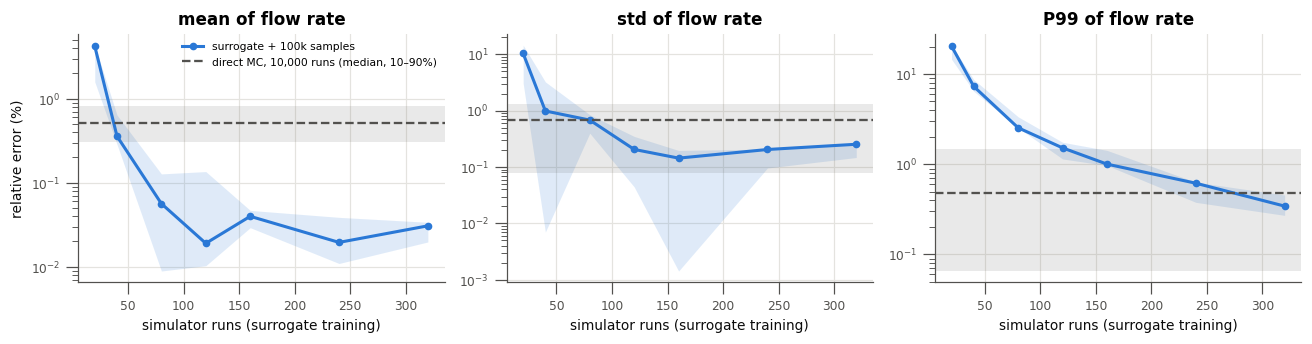

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharex=True)
for ax, stat in zip(axes, STATS):
    runs = sur_err.pivot(index="seed", columns="n", values=stat).to_numpy() * 100
    band(ax, sizes, runs, BLUE, "surrogate + 100k samples", marker="o", ms=4)
    q = np.quantile(mc_err[stat] * 100, [0.1, 0.5, 0.9])
    ax.axhspan(q[0], q[2], color=MUTED, alpha=0.12, lw=0)
    ax.axhline(q[1], color=MUTED, ls="--", lw=1.5, label=f"direct MC, {N_MC:,} runs (median, 10–90%)")
    ax.set(yscale="log", title=f"{stat} of flow rate", xlabel="simulator runs (surrogate training)")
axes[0].set_ylabel("relative error (%)")
axes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()

In [5]:
# Smallest design whose median error beats direct MC on every statistic.
med = sur_err.groupby("n")[list(STATS)].median()
ok = (med <= mc_err.median()).all(axis=1)
n_needed = int(ok[ok].index.min()) if ok.any() else None
overhead = sur_err.query("n == @n_needed")["seconds"].median() if n_needed else np.nan
print(f"surrogate matches a {N_MC:,}-run Monte Carlo study with {n_needed} runs "
      f"({N_MC / n_needed:.0f}x fewer); fit + 100k predictions took {overhead:.1f} s")
record("Monte Carlo UQ (borehole, 8 inputs)", f"direct MC, {N_MC:,} samples", N_MC, n_needed, overhead,
       "same or lower error on mean, std and P99")

surrogate matches a 10,000-run Monte Carlo study with 320 runs (31x fewer); fit + 100k predictions took 4.5 s


**Reading the result.** The surrogate's error falls quickly with training size. The direct
study's error does not move, because it is set by its 10,000 samples. For the mean and the
standard deviation, about 80 runs already beat the brute-force study. The 99th percentile is
the hardest statistic, because it depends on how well the surrogate captures the tail of the
response, and it sets the run count recorded in the ledger. If only means and spreads are
needed, the saving is several times larger. The same fitted surrogate can then be reused for
sensitivity analysis, what-if sweeps and dashboards at no further simulator cost.

<a id="al"></a>
## 3. Building a surrogate: which design, and when to stop

**Existing workflow.** Fix a design up front, usually a full-factorial grid (`k` levels per
input, `k^d` runs) or a random set, run all of it, then fit.

**With `multioutreg`.** Either use a space-filling Sobol design, or run `ActiveLearner`,
which adds one run at a time where the surrogate is least certain and can stop as soon as
the surrogate is good enough.

The metric is held-out NRMSE (RMSE over the test targets' standard deviation, averaged over
outputs) on 1,000 points. The question is how many runs each design needs to reach a target
NRMSE.

In [6]:
AL_PROBLEMS = {"branin_currin": (60, 0.05), "hartmann3": (80, 0.30)}  # budget, target NRMSE
al_results, al_overhead = {}, {}
for name, (budget, target) in AL_PROBLEMS.items():
    b = get_benchmark(name)
    Xt = b.sample(1000, method="random", seed=123)
    Yt = b(Xt)
    n_init = 2 * b.n_features + 2
    n = np.arange(n_init, budget + 1)
    curves = {}
    for acq in ("max_variance", "random"):
        runs = []
        for s in SEEDS:
            al = ActiveLearner(gp, b.bounds, acquisition=acq, n_candidates=512, random_state=s)
            t0 = time.perf_counter()
            hist = al.run(b, n_init=n_init, n_iter=budget - n_init, X_test=Xt, Y_test=Yt)
            if acq == "max_variance":
                al_overhead.setdefault(name, []).append(time.perf_counter() - t0)
            runs.append([h["nrmse"] for h in hist])
        curves[acq] = (n, np.array(runs))
    passive_n = np.arange(10, budget + 1, 5)
    curves["sobol"] = (passive_n, np.array([
        [heldout_metrics(gp().fit(X := b.sample(k, seed=s), b(X)), Xt, Yt)["nrmse"] for k in passive_n]
        for s in SEEDS]))
    ks = [k for k in range(3, 20) if k ** b.n_features <= 2.2 * budget]
    curves["grid"] = (np.array([k ** b.n_features for k in ks]), np.array([[
        heldout_metrics(gp().fit(X := grid_design(b, k), b(X)), Xt, Yt)["nrmse"] for k in ks]]))
    al_results[name] = curves

rows = []
for name, curves in al_results.items():
    target = AL_PROBLEMS[name][1]
    row = {"problem": name, "target NRMSE": target}
    for key, label in [("grid", "full-factorial grid"), ("random", "random"),
                       ("sobol", "Sobol"), ("max_variance", "active learning")]:
        x, runs = curves[key]
        hit = first_reaching(x, np.median(runs, 0), target)
        row[label] = "not reached" if hit is None else int(hit)
    rows.append(row)
runs_to_target = pd.DataFrame(rows).set_index("problem")
print("simulator runs needed to reach the target (median over seeds)")
print(runs_to_target.to_string())

simulator runs needed to reach the target (median over seeds)
               target NRMSE  full-factorial grid  random  Sobol  active learning
problem                                                                         
branin_currin          0.05                   49      51     50               45
hartmann3              0.30                  125      68     50               57


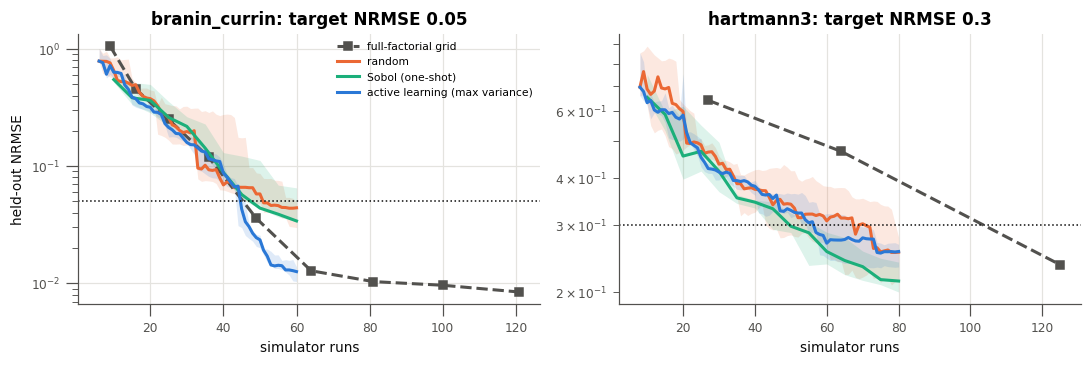

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, (name, curves) in zip(axes, al_results.items()):
    x, r = curves["grid"]
    ax.plot(x, r[0], color=MUTED, ls="--", marker="s", ms=5, label="full-factorial grid")
    band(ax, *curves["random"], ORANGE, "random")
    band(ax, *curves["sobol"], AQUA, "Sobol (one-shot)")
    band(ax, *curves["max_variance"], BLUE, "active learning (max variance)")
    ax.axhline(AL_PROBLEMS[name][1], color=INK, lw=1, ls=":")
    ax.set(yscale="log", title=f"{name}: target NRMSE {AL_PROBLEMS[name][1]}", xlabel="simulator runs")
axes[0].set_ylabel("held-out NRMSE")
axes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()

**Reading the result.** The large and reliable saving is **leaving the grid**. A full-factorial
grid spends its runs on repeated values of each input, and its size jumps in steps of `k^d`.
In three inputs the next grid after 64 runs has 125. Sobol and active designs reach the same
error with far fewer runs, and the gap widens with every added input.

Active learning against a good Sobol design is a closer race. On smooth, stationary
problems like these, max-variance sampling with a GP is itself a space-filling design, so it
does about as well as Sobol, ahead on Branin–Currin and behind on Hartmann-3 (see the
[active-learning tutorial](active_learning_benchmarks.ipynb) for more problems). What the
sequential loop adds is the option to **stop early**, which a one-shot design does not have.
Stopping needs an estimate of the surrogate's error *without* a hold-out set, since a hold-out
set costs simulator runs too. Two estimates are free:

- the GP's own predictive standard deviation averaged over the domain, standardized like NRMSE;
- 5-fold cross-validation on the runs collected so far (compute only, no new runs).

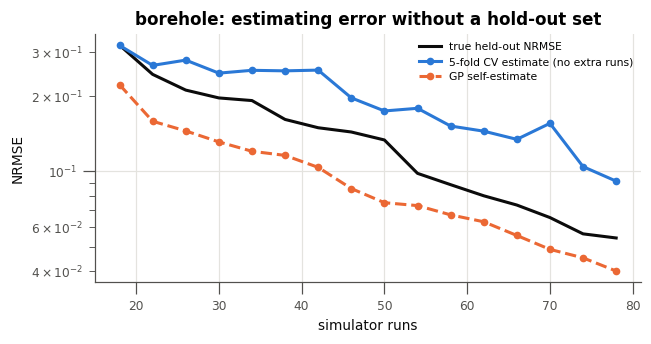

 runs  true  gp_estimate  cv_estimate
   18 0.319        0.222        0.318
   22 0.244        0.158        0.265
   26 0.211        0.145        0.278
   30 0.196        0.131        0.247
   34 0.192        0.120        0.253
   38 0.161        0.116        0.252
   42 0.149        0.104        0.254
   46 0.144        0.085        0.197
   50 0.133        0.075        0.174
   54 0.098        0.073        0.179
   58 0.088        0.067        0.152
   62 0.080        0.063        0.145
   66 0.073        0.055        0.134
   70 0.065        0.049        0.155
   74 0.056        0.045        0.104
   78 0.054        0.040        0.091


In [8]:
def gp_self_estimate(model, X_pool, Y_train):
    _, sd = model.predict(X_pool, return_std=True)
    return float(np.mean(np.sqrt((sd ** 2).mean(0)) / Y_train.std(0)))


def cv_nrmse(X, Y):
    P = np.zeros_like(Y)
    for tr, te in KFold(5, shuffle=True, random_state=0).split(X):
        P[te] = gp().fit(X[tr], Y[tr]).predict(X[te])
    return float(np.mean(np.sqrt(((P - Y) ** 2).mean(0)) / Y.std(0)))


b = get_benchmark("borehole")
Xt = b.sample(1000, method="random", seed=123)
Yt = b(Xt)
X_pool = b.sample(2048, seed=99)
al = ActiveLearner(gp, b.bounds, n_candidates=512, random_state=0)
hist = al.run(b, n_init=18, n_iter=62, X_test=Xt, Y_test=Yt)
check = []
for h in hist[::4]:
    k = h["n_evals"]
    model = gp().fit(al.X_[:k], al.Y_[:k])
    check.append(dict(runs=k, true=h["nrmse"], gp_estimate=gp_self_estimate(model, X_pool, al.Y_[:k]),
                      cv_estimate=cv_nrmse(al.X_[:k], al.Y_[:k])))
check = pd.DataFrame(check)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(check.runs, check.true, color=INK, label="true held-out NRMSE")
ax.plot(check.runs, check.cv_estimate, color=BLUE, marker="o", ms=4, label="5-fold CV estimate (no extra runs)")
ax.plot(check.runs, check.gp_estimate, color=ORANGE, marker="o", ms=4, ls="--", label="GP self-estimate")
ax.set(yscale="log", xlabel="simulator runs", ylabel="NRMSE", title="borehole: estimating error without a hold-out set")
ax.legend()
fig.tight_layout()
plt.show()
print(check.round(3).to_string(index=False))

**Use cross-validation as the stopping rule.** The GP's self-estimate is optimistic: the
model is more confident than it should be, so stopping on it would stop too early. CV on the
actively chosen points is pessimistic, because those points sit where the function is hardest,
so when "CV NRMSE ≤ target" fires, the true error is at or below the target. That makes it a
safe rule: it never stops too early, at the price of a few extra runs.

For the ledger, this scenario is the move from a full-factorial grid to a sequential design at
equal accuracy, on the 3-input Hartmann problem (the 2-input problem's grid happens to be
competitive). For the overhead, the measured time of the full active-learning run (all GP
refits) is charged.

In [9]:
row = runs_to_target.loc["hartmann3"]
n_grid = int(row["full-factorial grid"])
best_seq = min(v for k, v in row.items() if k in ("Sobol", "active learning") and v != "not reached")
print(f"hartmann3: grid {n_grid} runs vs {best_seq:.0f} runs for the best sequential/space-filling design")
record("Surrogate training design (Hartmann-3)", f"full-factorial grid ({n_grid} runs)", n_grid, int(best_seq),
       float(np.median(al_overhead["hartmann3"])), f"target NRMSE {AL_PROBLEMS['hartmann3'][1]}")

hartmann3: grid 125 runs vs 50 runs for the best sequential/space-filling design


<a id="opt"></a>
## 4. Design optimization

**Existing workflow.** Find the inputs that minimize an output (drag, stress, cost) by
sweeping a grid, or by random / hand-picked trial runs.

**With `multioutreg`.** `ActiveLearner(acquisition="ei")` runs Bayesian optimization:
each run goes where the expected improvement over the best value so far is largest.

The metric is the number of runs until the best value found is within 0.05 of the known
global minimum. Random search is simulated on 50 independent streams of up to 20,000 runs; the
grid is the smallest `k^d` grid whose best point is within the tolerance.

In [10]:
OPT = {"branin": 60, "hartmann3": 80}
TOL = 0.05
opt_rows, opt_overhead = [], {}
for name, budget in OPT.items():
    b = get_benchmark(name)
    n_init = 2 * b.n_features + 2
    ei_hits = []
    for s in range(5):
        al = ActiveLearner(gp, b.bounds, acquisition="ei", n_candidates=1024, random_state=s)
        t0 = time.perf_counter()
        hist = al.run(b, n_init=n_init, n_iter=budget - n_init)
        opt_overhead.setdefault(name, []).append(time.perf_counter() - t0)
        gap = np.array([h["best"] for h in hist]) - b.minimum
        hit = first_reaching([h["n_evals"] for h in hist], gap, TOL)
        ei_hits.append(np.inf if hit is None else hit)
    rs_hits = []
    for s in range(50):
        gap = np.minimum.accumulate(b(b.sample(20_000, method="random", seed=1000 + s)).ravel()) - b.minimum
        hit = first_reaching(np.arange(1, gap.size + 1), gap, TOL)
        rs_hits.append(np.inf if hit is None else hit)
    grid_hit = next((k ** b.n_features for k in range(3, 200)
                     if b(grid_design(b, k)).min() - b.minimum <= TOL), None)
    opt_rows.append({"problem": name, "Bayesian optimization (EI)": np.median(ei_hits),
                     "EI worst seed": np.max(ei_hits), "random search": np.median(rs_hits),
                     "full-factorial grid": grid_hit})
opt_table = pd.DataFrame(opt_rows).set_index("problem")
print(f"simulator runs until within {TOL} of the global minimum (median over seeds)")
print(opt_table.to_string())

simulator runs until within 0.05 of the global minimum (median over seeds)
           Bayesian optimization (EI)  EI worst seed  random search  full-factorial grid
problem                                                                                 
branin                           24.0             30          828.5                  196
hartmann3                        28.0             52          913.5                  512


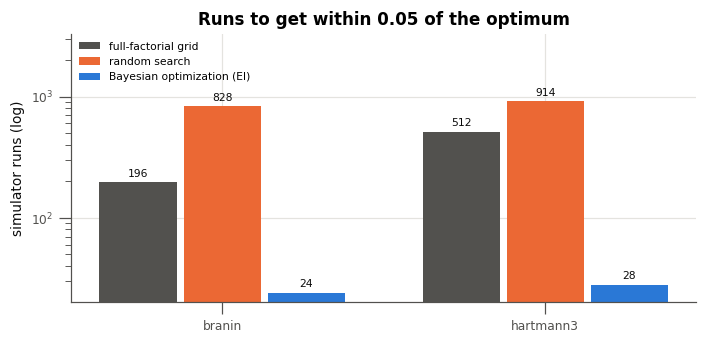

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
labels = list(opt_table.index)
cols = [("full-factorial grid", MUTED), ("random search", ORANGE), ("Bayesian optimization (EI)", BLUE)]
w = 0.26
for i, (col, color) in enumerate(cols):
    vals = opt_table[col].astype(float).to_numpy()
    xs = np.arange(len(labels)) + (i - 1) * w
    ax.bar(xs, vals, w * 0.92, color=color, label=col)
    for x, v in zip(xs, vals):
        ax.text(x, v * 1.08, f"{v:,.0f}", ha="center", va="bottom", fontsize=7, color=INK)
ax.set(yscale="log", xticks=range(len(labels)), xticklabels=labels, ylabel="simulator runs (log)",
       title=f"Runs to get within {TOL} of the optimum")
ax.set_ylim(top=ax.get_ylim()[1] * 3)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

for name in OPT:
    r = opt_table.loc[name]
    record(f"Design optimization ({name})", "random search", float(r["random search"]),
           float(r["Bayesian optimization (EI)"]), float(np.median(opt_overhead[name])),
           f"within {TOL} of the global minimum")

**Reading the result.** This is where the savings are largest. Random search and grids pay for
every run whether or not it is near the optimum. Expected improvement concentrates runs near
the optimum once the surrogate knows roughly where it is. The best point found is always a
real, evaluated run, so no separate confirmation run is needed.

<a id="mf"></a>
## 5. Multi-fidelity: let a cheap model carry most of the load

**Existing workflow.** Many teams have a cheap model (coarse mesh, empirical correlation,
reduced physics) next to the expensive one, but use the cheap model only for exploration by
hand and train any surrogate on the expensive model alone.

**With `multioutreg`.** `MultiFidelityActiveLearner` with the AR1 surrogate
`AdditiveCorrectionVFM` picks both *where* to run and *which fidelity*, per unit cost.

Costs: low fidelity 1, high fidelity 10 (so one cost unit is a tenth of a high-fidelity run).
The baseline is the existing workflow's best option, active learning on the high fidelity
only. The metric is held-out NRMSE against the high fidelity.

In [12]:
def ar1():
    return AdditiveCorrectionVFM(lo_surrogate_cls=gp, hi_surrogate_cls=gp, oof_cv=None)


def at_costs(cost, err, grid):
    # Error of the latest model fitted within each cost on the grid (step function).
    cost, err = np.asarray(cost), np.asarray(err)
    return np.array([err[cost <= c][-1] if np.any(cost <= c) else np.nan for c in grid])


MF = {"currin": (250, 600, 0.10), "park": (400, 600, 0.01)}  # MF budget, hi-only budget, target
mf_results, mf_overhead = {}, {}
for name, (budget_mf, budget_hi, target) in MF.items():
    b = get_benchmark(name)
    Xt = b.sample(1000, method="random", seed=123)
    Yt = b(Xt)
    sims = {lvl: (lambda X, lvl=lvl: b(X, lvl)) for lvl in b.levels}
    c_hi = b.costs["hi"]
    n_hi0 = b.n_features + 2
    grid = np.arange(10, budget_hi + 1, 10)
    curves = {"mf": [], "hi": []}
    for s in SEEDS:
        mf = MultiFidelityActiveLearner(ar1, b.bounds, b.levels, b.costs, n_candidates=256, random_state=s)
        t0 = time.perf_counter()
        hist = mf.run(sims, budget=budget_mf, n_init={"lo": 3 * n_hi0, "hi": n_hi0}, X_test=Xt, Y_test=Yt)
        mf_overhead.setdefault(name, []).append(time.perf_counter() - t0)
        mf_curve = at_costs([h["cost"] for h in hist], [h["nrmse"] for h in hist], grid)
        curves["mf"].append(np.where(grid <= budget_mf, mf_curve, np.nan))  # nothing beyond its budget
        al = ActiveLearner(gp, b.bounds, n_candidates=256, random_state=s)
        hist = al.run(lambda X: b(X, "hi"), n_init=n_hi0, n_iter=int(budget_hi / c_hi) - n_hi0, X_test=Xt, Y_test=Yt)
        curves["hi"].append(at_costs([h["n_evals"] * c_hi for h in hist], [h["nrmse"] for h in hist], grid))
    mf_results[name] = (grid, {k: np.array(v) for k, v in curves.items()})

rows = []
for name, (grid, curves) in mf_results.items():
    target = MF[name][2]
    c_mf = first_reaching(grid, np.nanmedian(curves["mf"], 0), target)
    c_hi = first_reaching(grid, np.nanmedian(curves["hi"], 0), target)
    rows.append({"problem": name, "target NRMSE": target, "high-fidelity only": c_hi, "multi-fidelity": c_mf})
mf_table = pd.DataFrame(rows).set_index("problem")
print("cost (low = 1, high = 10) to reach the target, median over seeds")
print(mf_table.to_string())

cost (low = 1, high = 10) to reach the target, median over seeds
         target NRMSE  high-fidelity only  multi-fidelity
problem                                                  
currin           0.10                 360             100
park             0.01                 510             330


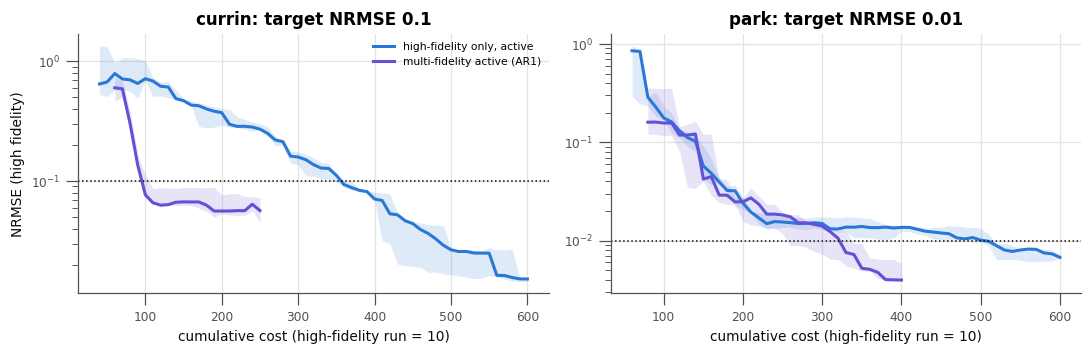

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for ax, (name, (grid, curves)) in zip(axes, mf_results.items()):
    band(ax, grid, curves["hi"], BLUE, "high-fidelity only, active")
    band(ax, grid, curves["mf"], VIOLET, "multi-fidelity active (AR1)")
    ax.axhline(MF[name][2], color=INK, lw=1, ls=":")
    ax.set(yscale="log", title=f"{name}: target NRMSE {MF[name][2]}", xlabel="cumulative cost (high-fidelity run = 10)")
axes[0].set_ylabel("NRMSE (high fidelity)")
axes[0].legend()
fig.tight_layout()
plt.show()

for name, r in mf_table.iterrows():
    if pd.notna(r["high-fidelity only"]) and pd.notna(r["multi-fidelity"]):
        # Express both in high-fidelity-run equivalents (cost / 10).
        record(f"Multi-fidelity ({name})", "active learning on high fidelity only",
               r["high-fidelity only"] / 10, r["multi-fidelity"] / 10,
               float(np.median(mf_overhead[name])), "cost in high-fidelity-run equivalents")

**Reading the result.** On Currin the cheap model is informative and the multi-fidelity learner
reaches the target at a fraction of the high-fidelity-only cost. Its error then levels off
near 0.06, though: the fused model is limited by how well the AR1 correction captures the gap
between levels, and with enough budget the high-fidelity-only learner goes lower. Multi-fidelity
buys a good-enough surrogate early. It does not replace high-fidelity data for very tight
targets. On Park the gain is smaller (1.5x), and the multi-fidelity learner keeps improving.
The saving depends on how well the cheap model correlates with the expensive one, and on
the cost ratio. The learner checks that correlation on the high-fidelity data
(`level_trust`), and keeps at least 25% of spending on the high fidelity, so a useless
cheap model wastes little (see the [active-learning tutorial](active_learning_benchmarks.ipynb),
section 8).

<a id="screen"></a>
## 6. Model-selection compute: pre-screening

The previous scenarios save simulator runs. This one saves the analyst's compute. Picking a
surrogate means a cross-validated grid search over many model families, repeated every time
the data changes. `AutoDetectMultiOutputRegressor(pre_screen=True)` first runs cheap
statistical tests (linearity, normality, heteroscedasticity, sample size), then skips
families the data does not justify. For example, it drops tree ensembles and MLPs when a
linear model is adequate, and it drops exact GPs above 300 rows.

Ten candidate families, 5-fold CV, three outputs; held-out R² on 1,000 test rows.

In [14]:
from sklearn.ensemble import (ExtraTreesRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, RandomForestRegressor)
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

from multioutreg.model_selection import AutoDetectMultiOutputRegressor


def candidates():
    sc = lambda est: make_pipeline(StandardScaler(), est)
    return [
        (LinearRegression(), {}),
        (DecisionTreeRegressor(random_state=0), {"max_depth": [4, 8, None]}),
        (sc(KNeighborsRegressor()), {"kneighborsregressor__n_neighbors": [3, 5, 9]}),
        (sc(SVR()), {"svr__C": [1.0, 10.0, 100.0], "svr__gamma": ["scale", 0.1]}),
        (sc(GaussianProcessRegressor(normalize_y=True)), {}),
        (RandomForestRegressor(random_state=0), {"n_estimators": [100, 300], "max_depth": [None, 8]}),
        (ExtraTreesRegressor(random_state=0), {"n_estimators": [100, 300], "max_depth": [None, 8]}),
        (GradientBoostingRegressor(random_state=0), {"n_estimators": [100, 300], "max_depth": [2, 4]}),
        (HistGradientBoostingRegressor(random_state=0), {"learning_rate": [0.05, 0.1], "max_iter": [100, 300]}),
        (sc(MLPRegressor(max_iter=1000, random_state=0)),
         {"mlpregressor__hidden_layer_sizes": [(64,), (64, 64)], "mlpregressor__alpha": [1e-4, 1e-2]}),
    ]


rng = np.random.default_rng(0)
n_train, n_test = 200, 1000
X = rng.uniform(-1, 1, size=(n_train + n_test, 6))
Y_lin = X @ rng.normal(size=(6, 3)) + 0.2 * rng.normal(size=(n_train + n_test, 3))
Y_mix = Y_lin.copy()
Y_mix[:, 0] = np.sin(3 * X[:, 0]) + X[:, 1] ** 2 + 0.1 * rng.normal(size=n_train + n_test)
DATASETS = {"linear (3 linear outputs)": Y_lin, "mixed (1 nonlinear + 2 linear outputs)": Y_mix}

rows = []
for label, Y in DATASETS.items():
    for pre_screen in (False, True):
        est, grids = zip(*candidates())
        model = AutoDetectMultiOutputRegressor(list(est), list(grids), cv=5, pre_screen=pre_screen)
        t0 = time.perf_counter()
        model.fit(X[:n_train], Y[:n_train])
        seconds = time.perf_counter() - t0
        P, Yte = model.predict(X[n_train:]), Y[n_train:]
        r2 = 1 - ((P - Yte) ** 2).sum(0) / ((Yte - Yte.mean(0)) ** 2).sum(0)
        rows.append({"data": label, "pre_screen": pre_screen, "fit seconds": round(seconds, 1),
                     "families searched / output": [len(s) for s in model.selection_scores_],
                     "test R² / output": np.round(r2, 3).tolist()})
screen_table = pd.DataFrame(rows)
print(screen_table.to_string(index=False))

                                  data  pre_screen  fit seconds families searched / output     test R² / output
             linear (3 linear outputs)       False         61.3               [10, 10, 10] [0.968, 0.986, 0.96]
             linear (3 linear outputs)        True          4.0                  [5, 5, 5] [0.968, 0.986, 0.96]
mixed (1 nonlinear + 2 linear outputs)       False         65.5               [10, 10, 10] [0.962, 0.986, 0.96]
mixed (1 nonlinear + 2 linear outputs)        True         25.1                 [10, 5, 5] [0.962, 0.986, 0.96]


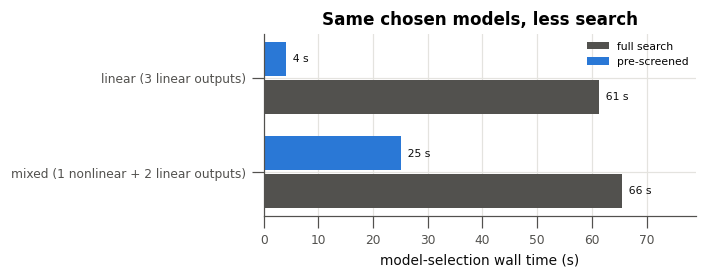

pre-screening cut model-selection time by 77% (127 s -> 29 s) on these two datasets


In [15]:
fig, ax = plt.subplots(figsize=(6.5, 2.6))
labels = list(DATASETS)
for i, (ps, color, name) in enumerate([(False, MUTED, "full search"), (True, BLUE, "pre-screened")]):
    vals = screen_table[screen_table.pre_screen == ps]["fit seconds"].to_numpy()
    ys = np.arange(len(labels)) + (0.2 if not ps else -0.2)
    ax.barh(ys, vals, 0.36, color=color, label=name)
    for y, v in zip(ys, vals):
        ax.text(v, y, f"  {v:.0f} s", va="center", fontsize=7, color=INK)
ax.set(yticks=range(len(labels)), yticklabels=labels, xlabel="model-selection wall time (s)",
       title="Same chosen models, less search")
ax.invert_yaxis()
ax.set_xlim(right=ax.get_xlim()[1] * 1.15)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

full = screen_table[~screen_table.pre_screen]["fit seconds"].sum()
fast = screen_table[screen_table.pre_screen]["fit seconds"].sum()
print(f"pre-screening cut model-selection time by {100 * (1 - fast / full):.0f}% "
      f"({full:.0f} s -> {fast:.0f} s) on these two datasets")

**Reading the result.** On the linear outputs pre-screening skips the nonlinear families, and
the search picks the same linear model as the full search with the same held-out R² in a
fraction of the time. On the nonlinear output the tree ensembles stay in, so the saving there
comes only from the linear outputs. The saving grows with the size of the candidate list:
`AutoDetectMultiOutputRegressor.with_vendored_surrogates()` searches 18 or more families.

Pre-screening is not free of risk. When a heavy model would have scored slightly better on a
nonlinear output, skipping it can cost a little accuracy. Compare against the full search
once on a representative dataset before switching it on everywhere.

This scenario is not in the ledger below, because it saves analyst compute rather than
simulator runs.

<a id="ledger"></a>
## 7. The ledger

Each scenario above recorded the runs its existing-workflow baseline needed and the runs
`multioutreg` needed for the same result. Here they are priced with the cost model from
section 1. `multioutreg`'s own compute is the measured wall time of its surrogate fitting
and candidate scoring, charged as single-core hours at the same price.

In [16]:
def price(ledger, cost):
    df = pd.DataFrame(ledger)
    for col in ("runs_baseline", "runs_multioutreg"):
        df[col] = np.ceil(df[col].astype(float)).astype(int)
    df["runs_saved"] = df.runs_baseline - df.runs_multioutreg
    df["fewer_runs"] = df.runs_baseline / df.runs_multioutreg
    df["overhead_core_h"] = df.overhead_s / 3600
    df["usd_saved"] = cost.usd(df.runs_saved) - df.overhead_core_h * cost.usd_per_core_hour
    df["core_hours_saved"] = cost.core_hours(df.runs_saved) - df.overhead_core_h
    df["wall_hours_saved"] = cost.wall_hours(df.runs_baseline) - cost.wall_hours(df.runs_multioutreg) - df.overhead_s / 3600
    return df


ledger = price(LEDGER, COST)
show = ledger[["scenario", "baseline", "runs_baseline", "runs_multioutreg", "fewer_runs",
               "usd_saved", "core_hours_saved", "wall_hours_saved", "overhead_s"]]
print(show.to_string(index=False, formatters={
    "fewer_runs": "{:.1f}x".format, "usd_saved": "${:,.0f}".format,
    "core_hours_saved": "{:,.0f}".format, "wall_hours_saved": "{:,.0f}".format,
    "overhead_s": "{:.0f}".format}))

                              scenario                              baseline  runs_baseline  runs_multioutreg fewer_runs usd_saved core_hours_saved wall_hours_saved overhead_s
   Monte Carlo UQ (borehole, 8 inputs)             direct MC, 10,000 samples          10000               320      31.2x   $79,376          619,520            2,420          5
Surrogate training design (Hartmann-3)        full-factorial grid (125 runs)            125                50       2.5x      $615            4,800               18          8
          Design optimization (branin)                         random search            829                24      34.5x    $6,601           51,520              202          9
       Design optimization (hartmann3)                         random search            914                28      32.6x    $7,265           56,704              222         12
               Multi-fidelity (currin) active learning on high fidelity only             36                10       3.6x

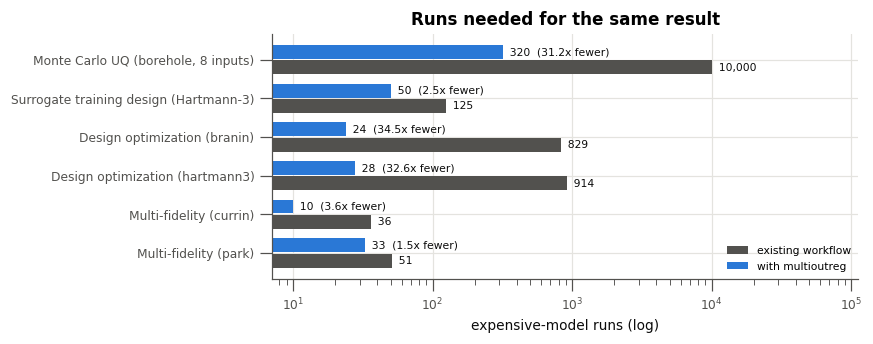

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.2))
names = ledger.scenario.tolist()
ys = np.arange(len(names))
ax.barh(ys + 0.2, ledger.runs_baseline, 0.36, color=MUTED, label="existing workflow")
ax.barh(ys - 0.2, ledger.runs_multioutreg, 0.36, color=BLUE, label="with multioutreg")
for y, (nb, nm, f) in enumerate(zip(ledger.runs_baseline, ledger.runs_multioutreg, ledger.fewer_runs)):
    ax.text(nb, y + 0.2, f"  {nb:,}", va="center", fontsize=7, color=INK)
    ax.text(nm, y - 0.2, f"  {nm:,}  ({f:.1f}x fewer)", va="center", fontsize=7, color=INK)
ax.set(xscale="log", yticks=ys, yticklabels=names, xlabel="expensive-model runs (log)",
       title="Runs needed for the same result")
ax.set_xlim(right=ax.get_xlim()[1] * 8)
ax.invert_yaxis()
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

**Your numbers.** The run counts are properties of the problems. The money and time are
properties of your simulator. Re-price the same ledger for a cheap and an expensive model
without re-running anything:

In [18]:
PROFILES = {
    "cheap: 10 min, 4 cores, no fixed cost": SimulationCost(1 / 6, 4, 0.05, 0.0, 32),
    "default: 2 h, 32 cores, $5 fixed": COST,
    "expensive: 24 h, 128 cores, $50 fixed": SimulationCost(24, 128, 0.05, 50.0, 4),
}
rows = []
for label, cost in PROFILES.items():
    df = price(LEDGER, cost)
    rows.append({"cost profile": label, "per run": f"${cost.usd(1):,.2f}",
                 "total $ saved": f"${df.usd_saved.sum():,.0f}",
                 "core-hours saved": f"{df.core_hours_saved.sum():,.0f}",
                 "wall-clock days saved": f"{df.wall_hours_saved.sum() / 24:,.1f}"})
print(pd.DataFrame(rows).to_string(index=False))

                         cost profile per run total $ saved core-hours saved wall-clock days saved
cheap: 10 min, 4 cores, no fixed cost   $0.03          $383            7,660                   2.5
     default: 2 h, 32 cores, $5 fixed   $8.20       $94,218          735,360                 119.7
expensive: 24 h, 128 cores, $50 fixed $203.60    $2,339,364       35,297,280               2,873.0


The cheap profile is the honest boundary case. When a run takes minutes, the money saved is
small and most of the value is calendar time. The Monte Carlo study is the exception, because
10,000 runs are costly even at a few cents each. When a run takes a day on a cluster,
each run saved is worth more than all of `multioutreg`'s compute in this notebook combined.

<a id="integration"></a>
## 8. Plugging into your pipeline

None of this requires the simulator to be a Python function. Real simulators run on a cluster
queue or in a lab, and `ActiveLearner` exposes the same loop as `ask` / `tell`: ask for the
next batch of inputs, run them however you run them today, tell the results back. Only the
DOE step of the existing pipeline changes; the job scripts, the queue and the post-processing
stay as they are.

The cell below uses a stand-in `submit_and_wait` with the borehole function. In practice it
would write input decks, submit them with `sbatch` / `qsub` or your workflow manager, wait,
and parse the outputs. Batches of `parallel_jobs` keep every queue slot busy, and the
cross-validation stopping rule from section 3 ends the loop.

In [19]:
b = get_benchmark("borehole")


def submit_and_wait(X):
    # Stand-in for: write input decks, submit to the scheduler, wait, parse results.
    return b(X)


TARGET = 0.10  # stop when cross-validated NRMSE is at or below this
learner = ActiveLearner(gp, b.bounds, batch_size=COST.parallel_jobs, random_state=0)

X0 = learner.initial_design(16)            # round 0: a small space-filling design
learner.tell(X0, submit_and_wait(X0))
for round_ in range(1, 20):
    err = cv_nrmse(learner.X_, learner.Y_)
    print(f"round {round_:>2}: {len(learner.X_):>3} runs, CV NRMSE {err:.3f}")
    if err <= TARGET:
        break
    X_next = learner.ask()                  # the next batch of 8 inputs to run
    learner.tell(X_next, submit_and_wait(X_next))

surrogate = learner.fit()                   # a fitted multioutreg surrogate
Xt = b.sample(1000, method="random", seed=123)
print(f"stopped after {len(learner.X_)} runs; true held-out NRMSE {heldout_metrics(surrogate, Xt, b(Xt))['nrmse']:.3f}")

round  1:  16 runs, CV NRMSE 0.180


round  2:  24 runs, CV NRMSE 0.400


round  3:  32 runs, CV NRMSE 0.242


round  4:  40 runs, CV NRMSE 0.224


round  5:  48 runs, CV NRMSE 0.167


round  6:  56 runs, CV NRMSE 0.163


round  7:  64 runs, CV NRMSE 0.153


round  8:  72 runs, CV NRMSE 0.138


round  9:  80 runs, CV NRMSE 0.094
stopped after 80 runs; true held-out NRMSE 0.052


The stop is conservative, as section 3 predicted: the loop stops when the cross-validated
estimate reaches the target, and by then the true error is usually well below it. Raise
`TARGET` to stop sooner. The rule errs towards spending a few extra runs, not towards
handing over a surrogate that is worse than you asked for.

The fitted surrogate is a normal `multioutreg` estimator. It can be scored with the
performance metrics, wrapped with conformal prediction intervals, written to an HTML report,
or saved with `joblib` and loaded in downstream tools.

<a id="caveats"></a>
## 9. When the savings disappear

These results are on analytic benchmarks chosen to be representative, not best cases. The
savings shrink or vanish when:

- **The simulator is cheap.** If a run takes seconds, run it directly. A surrogate earns its
  keep when runs are expensive or the analysis needs many of them.
- **The response is rough or high-dimensional.** A GP with 8 inputs (borehole) works well;
  with 50 inputs, or discontinuities and regime changes, many more training runs are needed.
  Use the hold-out or CV check before trusting a surrogate for a decision.
- **A good space-filling design is already in place.** Against Sobol, max-variance active
  learning is roughly break-even on smooth problems (section 3). The remaining gain is the
  stopping rule.
- **The cheap fidelity is weakly correlated.** Multi-fidelity savings depend on it. The
  learner's safeguards limit the waste, but do not create savings that are not there.
- **Final decisions still need the real model.** A design picked on a surrogate should be
  confirmed with a real run. Bayesian optimization already evaluates its best point. For
  surrogate-only analyses, budget a handful of confirmation runs.